# 电信客户流失预测

整体思路：目标 → EDA → 预处理 → 建模 → 结论以及改进建议

本项目基于kaggle上的数据集，做了一个 Telco 电信客户数据预测流失，核心特征为合同类型、在网时长与月费（含套餐、支付方式）。逻辑回归 AUC 0.840、Recall 0.802，优于未调 class_weight 的随机森林（Recall 仅 0.449），补 balanced 后 Recall 明显回升。业务上建议将月付客户转为长合同、重点挽留在网不足一年的新客户，并为高价光纤客户补充增值服务。

## 业务目标

提前识别可能流失的客户，以便精准挽留——获客成本远高于留存。

评估指标选 AUC 和 Recall，而非 Accuracy：流失样本只占 26.5%，全预测“不流失”也有 73.5% 的准确率，却抓不到真正要走的客户。Recall 看能拦回多少流失客户，AUC 看能否把高危客户排在前面。

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style('whitegrid')
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei', 'SimHei', 'Arial Unicode MS']
plt.rcParams['axes.unicode_minus'] = False

df = pd.read_csv('TelcoChurn.csv')
print(df.shape)
df.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


## EDA：找与流失强相关的特征

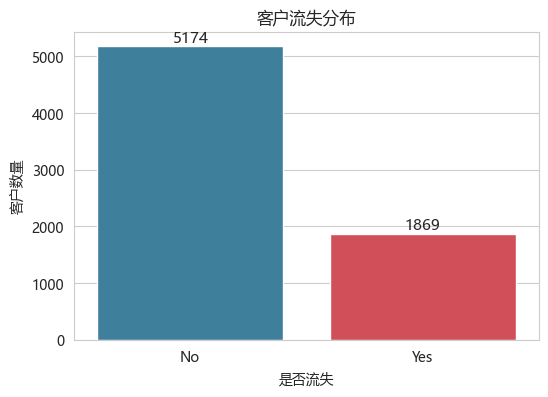

Churn
No     73.5
Yes    26.5
Name: proportion, dtype: float64


In [3]:
plt.figure(figsize=(6, 4))
ax = sns.countplot(x='Churn', hue='Churn', data=df, palette=['#2E86AB', '#E63946'], legend=False)
plt.title('客户流失分布')
plt.xlabel('是否流失'); plt.ylabel('客户数量')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom', fontsize=11)
plt.show()
print((df['Churn'].value_counts(normalize=True) * 100).round(1))

流失率 26.5%，类别不平衡 → 用 AUC/Recall。

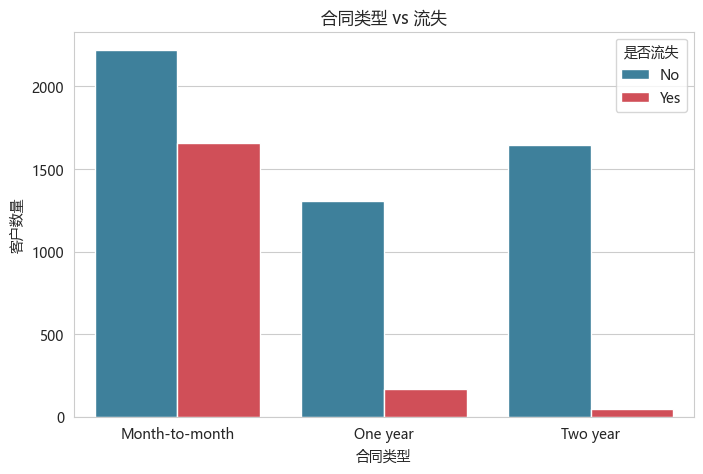

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: Churn, dtype: float64


In [4]:
plt.figure(figsize=(8, 5))
sns.countplot(x='Contract', hue='Churn', data=df, palette=['#2E86AB', '#E63946'])
plt.title('合同类型 vs 流失')
plt.xlabel('合同类型'); plt.ylabel('客户数量')
plt.legend(title='是否流失')
plt.show()
print(df.groupby('Contract')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).round(1))

月付 42.7% / 一年 11.3% / 两年 2.8% → 合同类型是重点

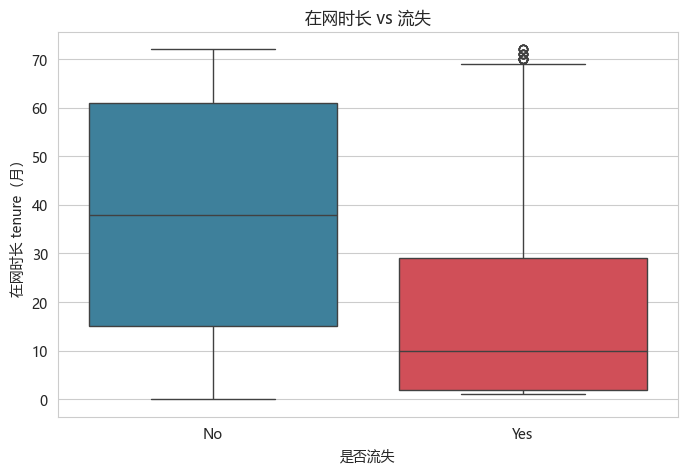

Churn
No     37.6
Yes    18.0
Name: tenure, dtype: float64


In [5]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn', y='tenure', hue='Churn', data=df, palette=['#2E86AB', '#E63946'], legend=False)
plt.title('在网时长 vs 流失')
plt.xlabel('是否流失'); plt.ylabel('在网时长 tenure（月）')
plt.show()
print(df.groupby('Churn')['tenure'].mean().round(1))

流失客户在网约 18 个月 vs 未流失 38 → 新客户更容易流失

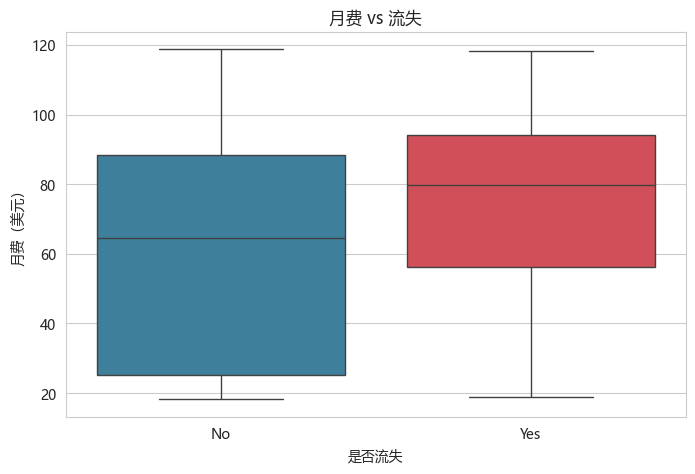

Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [6]:
plt.figure(figsize=(8, 5))
sns.boxplot(x='Churn', y='MonthlyCharges', hue='Churn', data=df, palette=['#2E86AB', '#E63946'], legend=False)
plt.title('月费 vs 流失')
plt.xlabel('是否流失'); plt.ylabel('月费（美元）')
plt.show()
print(df.groupby('Churn')['MonthlyCharges'].mean().round(2))

流失客户月费 74 vs 61 美元 → 高月费更易流失。

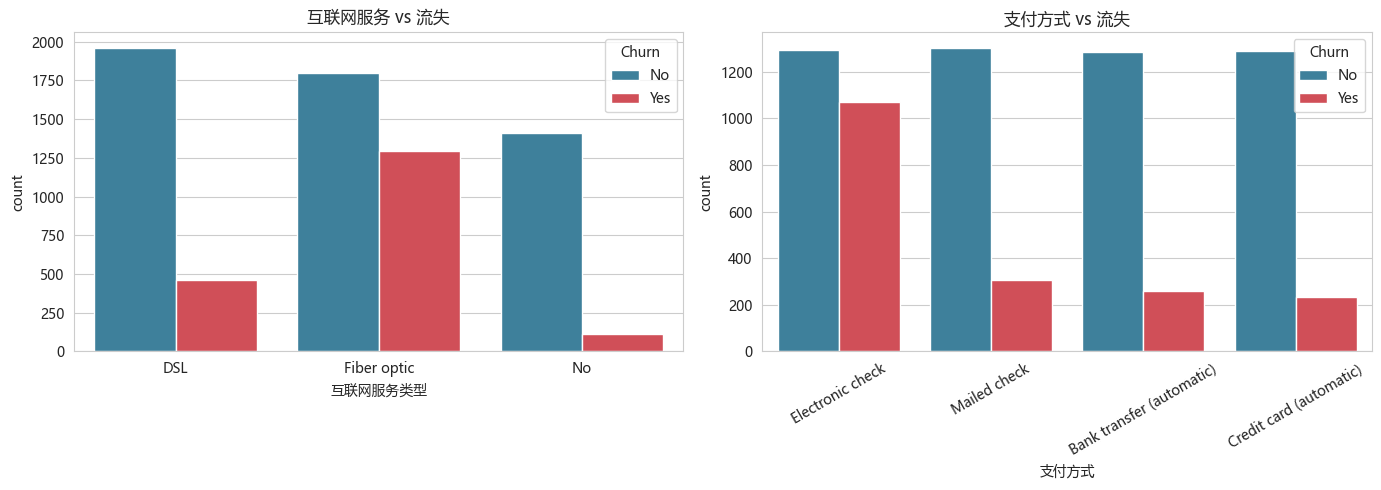

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4
Name: Churn, dtype: float64
PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1
Name: Churn, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(x='InternetService', hue='Churn', data=df, palette=['#2E86AB', '#E63946'], ax=axes[0])
axes[0].set_title('互联网服务 vs 流失'); axes[0].set_xlabel('互联网服务类型')
sns.countplot(x='PaymentMethod', hue='Churn', data=df, palette=['#2E86AB', '#E63946'], ax=axes[1])
axes[1].set_title('支付方式 vs 流失'); axes[1].set_xlabel('支付方式')
axes[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()
print(df.groupby('InternetService')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).round(1))
print(df.groupby('PaymentMethod')['Churn'].apply(lambda x: (x == 'Yes').mean() * 100).round(1))

光纤 41.9%、电子支票 45.3% 流失率高 → 保留进模型。

## 预处理

In [8]:
print(df['TotalCharges'].dtype)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
print("缺失数", df['TotalCharges'].isna().sum())
print(df.loc[df['TotalCharges'].isna(), 'tenure'].unique())

object
缺失数 11
[0]


TotalCharges 缺失 = tenure 0 的新客户，累计消费就是 0 

In [9]:
df['TotalCharges'] = df['TotalCharges'].fillna(0)

In [10]:
# 剔除：customerID(编号)、gender(无关)、电话服务(区分度低)、家庭状况(弱相关)、冗余增值服务
df.drop(columns=['customerID', 'gender', 'PhoneService', 'MultipleLines',
                 'Partner', 'Dependents', 'OnlineBackup', 'DeviceProtection',
                 'StreamingTV', 'StreamingMovies'], inplace=True)

In [11]:
# 文字 -> 数字：Yes/No->0/1、合同->0/1/2、多类别->独热
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})
df['OnlineSecurity'] = df['OnlineSecurity'].map({'Yes': 1, 'No': 0, 'No internet service': 0})
df['TechSupport'] = df['TechSupport'].map({'Yes': 1, 'No': 0, 'No internet service': 0})
df['PaperlessBilling'] = df['PaperlessBilling'].map({'Yes': 1, 'No': 0})
df['Contract'] = df['Contract'].map({'Month-to-month': 0, 'One year': 1, 'Two year': 2})
df = pd.get_dummies(df, columns=['InternetService', 'PaymentMethod'], drop_first=True)

## 建模：逻辑回归 vs 随机森林

In [12]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Churn'])
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, recall_score, confusion_matrix

lr = LogisticRegression(class_weight='balanced', max_iter=3000, random_state=42)  # balanced=处理不平衡
lr.fit(X_train, y_train)
y_pred_lr = lr.predict(X_test)
y_prob_lr = lr.predict_proba(X_test)[:, 1]
lr_auc = roc_auc_score(y_test, y_prob_lr)
lr_recall = recall_score(y_test, y_pred_lr)
lr_cm = confusion_matrix(y_test, y_pred_lr)
print(f"逻辑回归  AUC {lr_auc:.3f}  Recall {lr_recall:.3f}")
print(lr_cm)

逻辑回归  AUC 0.840  Recall 0.802
[[737 298]
 [ 74 300]]


In [14]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(max_depth=5, n_estimators=100, random_state=42)  # depth=5 防过拟合
rf.fit(X_train, y_train)
y_pred_rf = rf.predict(X_test)
y_prob_rf = rf.predict_proba(X_test)[:, 1]
rf_auc = roc_auc_score(y_test, y_prob_rf)
rf_recall = recall_score(y_test, y_pred_rf)
rf_cm = confusion_matrix(y_test, y_pred_rf)
print(f"随机森林  AUC {rf_auc:.3f}  Recall {rf_recall:.3f}")
print(rf_cm)

随机森林  AUC 0.845  Recall 0.449
[[951  84]
 [206 168]]


     模型    AUC  Recall
0  逻辑回归  0.840   0.802
1  随机森林  0.845   0.449


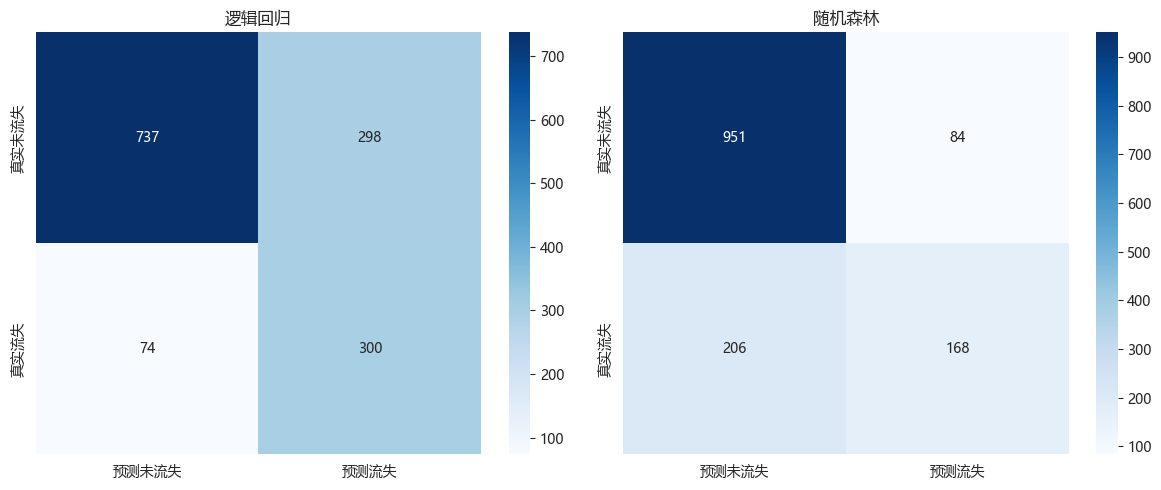

In [15]:
print(pd.DataFrame({'模型': ['逻辑回归', '随机森林'],
                     'AUC': [lr_auc, rf_auc], 'Recall': [lr_recall, rf_recall]}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, cm, t in zip(axes, [lr_cm, rf_cm], ['逻辑回归', '随机森林']):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['预测未流失', '预测流失'], yticklabels=['真实未流失', '真实流失'])
    ax.set_title(t)
plt.tight_layout()
plt.show()

逻辑回归 AUC 0.840 / Recall 0.802，随机森林 0.845 / 0.449。

AUC 相近，Recall 相差较大——因为随机森林没设 balanced、输出概率偏低，默认 0.5 阈值漏掉大半流失客户。**逻辑回归更适合作业务首选**（Recall 高）。

In [16]:
# 补一个 class_weight='balanced' 的随机森林，验证类别不平衡是不是 RF Recall 低的原因
rf_bal = RandomForestClassifier(max_depth=5, n_estimators=100, class_weight='balanced', random_state=42)
rf_bal.fit(X_train, y_train)
y_prob_rf_bal = rf_bal.predict_proba(X_test)[:, 1]
y_pred_rf_bal = rf_bal.predict(X_test)
rf_bal_auc = roc_auc_score(y_test, y_prob_rf_bal)
rf_bal_recall = recall_score(y_test, y_pred_rf_bal)
print(f"随机森林(balanced)  AUC {rf_bal_auc:.3f}  Recall {rf_bal_recall:.3f}")

随机森林(balanced)  AUC 0.844  Recall 0.797


对比：未加 balanced 的 RF Recall 只有 0.449，加上 class_weight='balanced' 后 Recall 明显回升到0.797、AUC 基本持平——说明上一节 RF 的 Recall 低主要是类别不平衡造成的，少数类在默认 0.5 阈值下被漏掉，不是模型本身的问题。

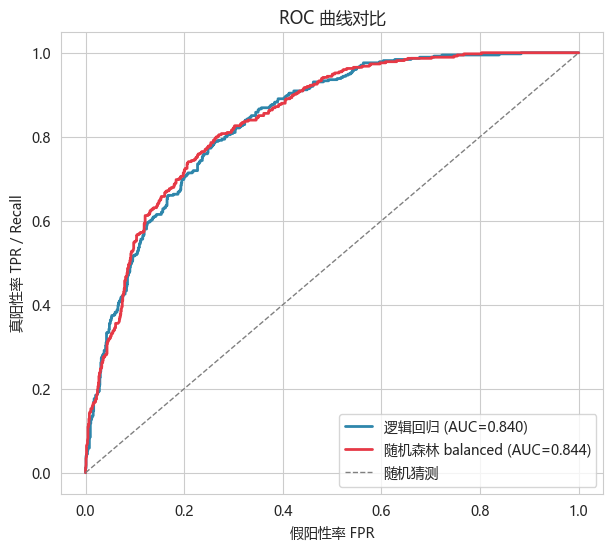

In [17]:
from sklearn.metrics import roc_curve

# LR 与 balanced RF 的 ROC 曲线对比，标注 AUC
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf_bal)

plt.figure(figsize=(7, 6))
plt.plot(fpr_lr, tpr_lr, lw=2, color='#2E86AB', label=f'逻辑回归 (AUC={lr_auc:.3f})')
plt.plot(fpr_rf, tpr_rf, lw=2, color='#E63946', label=f'随机森林 balanced (AUC={rf_bal_auc:.3f})')
plt.plot([0, 1], [0, 1], lw=1, ls='--', color='gray', label='随机猜测')
plt.xlabel('假阳性率 FPR')
plt.ylabel('真阳性率 TPR / Recall')
plt.title('ROC 曲线对比')
plt.legend(loc='lower right')
plt.show()

## 结论建议

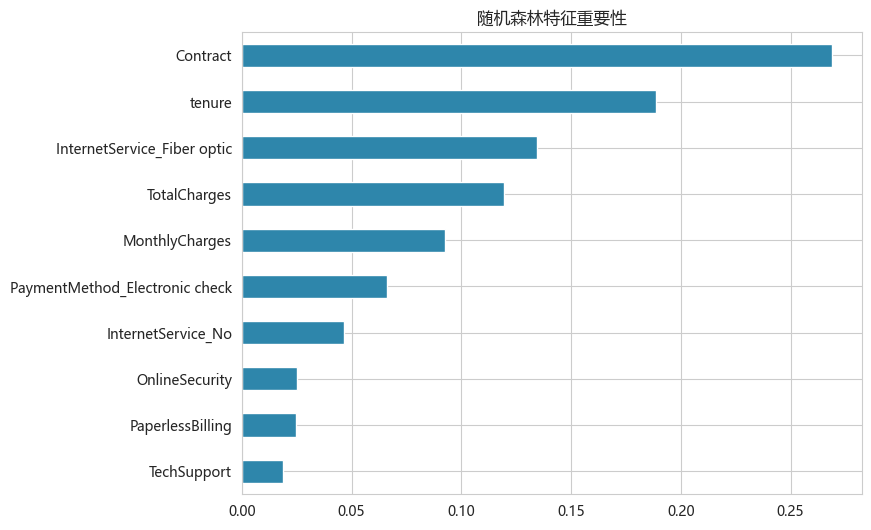

Contract                                 0.269
tenure                                   0.189
InternetService_Fiber optic              0.135
TotalCharges                             0.119
MonthlyCharges                           0.092
PaymentMethod_Electronic check           0.066
InternetService_No                       0.046
OnlineSecurity                           0.025
PaperlessBilling                         0.025
TechSupport                              0.019
SeniorCitizen                            0.007
PaymentMethod_Mailed check               0.004
PaymentMethod_Credit card (automatic)    0.004
dtype: float64


In [18]:
importance = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
importance.head(10).plot(kind='barh', color='#2E86AB')
plt.gca().invert_yaxis()
plt.title('随机森林特征重要性')
plt.show()
print(importance.round(3))

In [19]:
print(pd.Series(lr.coef_[0], index=X.columns).sort_values(ascending=False).round(3))

InternetService_Fiber optic              0.550
PaymentMethod_Electronic check           0.447
PaperlessBilling                         0.382
SeniorCitizen                            0.236
PaymentMethod_Mailed check               0.023
MonthlyCharges                           0.004
TotalCharges                             0.000
PaymentMethod_Credit card (automatic)   -0.010
tenure                                  -0.048
TechSupport                             -0.377
OnlineSecurity                          -0.487
Contract                                -0.725
InternetService_No                      -0.914
dtype: float64


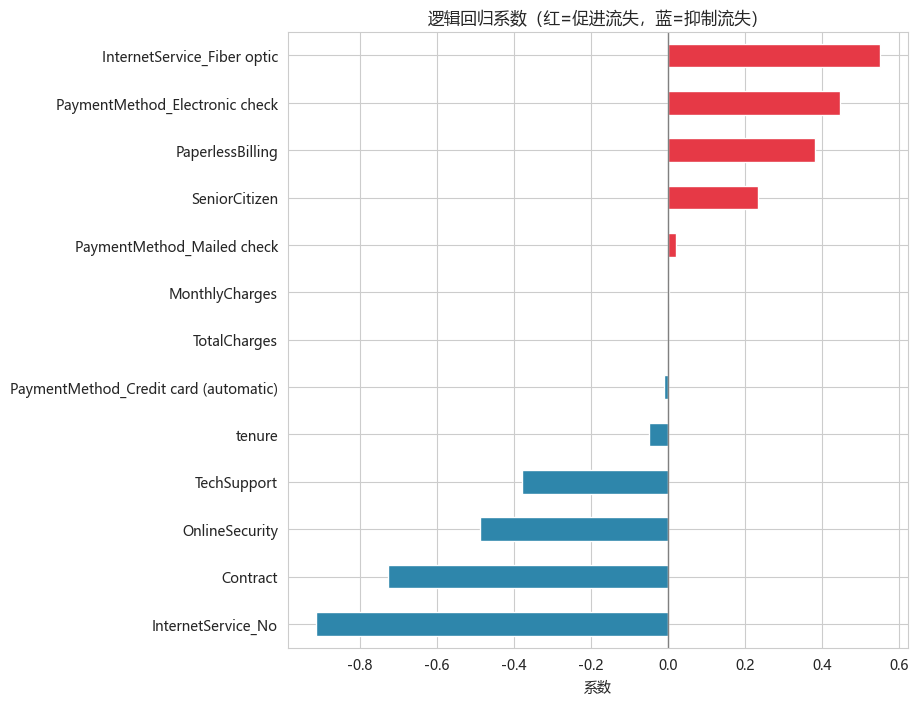

In [20]:
# LR 系数条形图：正系数促进流失(红)，负系数抑制流失(蓝)，竖线为零线
coef = pd.Series(lr.coef_[0], index=X.columns).sort_values()
colors = ['#E63946' if c > 0 else '#2E86AB' for c in coef.values]

plt.figure(figsize=(8, 8))
coef.plot(kind='barh', color=colors)
plt.axvline(0, color='gray', lw=1)
plt.title('逻辑回归系数（红=促进流失，蓝=抑制流失）')
plt.xlabel('系数')
plt.show()


影响流失的三个主要因素：合同类型（重要性最高，系数 -0.73）、在网时长 tenure、高价套餐（光纤 +0.55、电子支票 +0.45）。

高危流失客户的可能具有的特征：月付合同，入网时间短，高价光纤，电子支票，无增值服务

建议：
1. 提供新方案把月付客户转成长合同
2. 服务好入网时间较短的新客户，可以通过回访来增加新客户留下来的概率
3. 给高价光纤客户补增值服务

